# Homework 2: Regression

Machine Learning Zoomcamp 2026
- Fabián Bayas Moscoso

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

## Get Data

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")

df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


## Preparing the dataset

In [3]:
# Select and prepare the dataset
selected_columns = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

# Create a new dataframe with selected features
df_prepared = df[selected_columns].copy()


## EDA

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

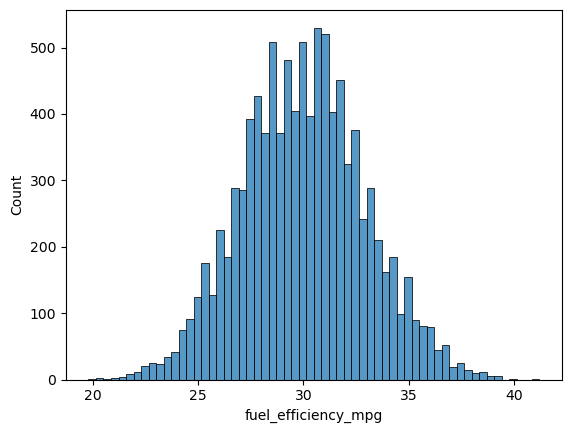

In [4]:
# Look at the fuel_efficiency_mpg variable. Does it have a long tail?

%matplotlib inline

sns.histplot(df_prepared['fuel_efficiency_mpg'])

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

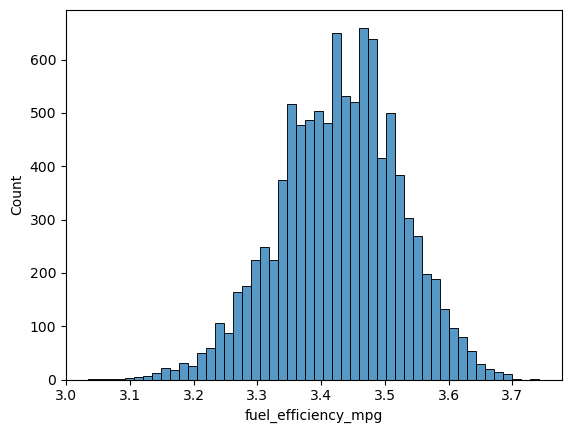

In [5]:
fuel_logs = np.log1p(df_prepared.fuel_efficiency_mpg)

sns.histplot(fuel_logs, bins=50)

## 1. There's one column with missing values. What is it?

In [6]:
df_prepared.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

## 2. What's the median (50% percentile) for variable 'horsepower'?

In [7]:
df_prepared['horsepower'].median()

254.0

Prepare and split the dataset

In [8]:
n = len(df_prepared)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

## 3. Filling NAs
- We need to deal with missing values for the column from Q1.
- We have two options: fill it with 0 or with the mean of this variable.
- Try both options. For each, train a linear regression model without regularization using the code from the lessons.
- For computing the mean, use the training only!
- Use the validation dataset to evaluate the models and compare the RMSE of each option.
- Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
- Which option gives better RMSE?

In [9]:
# QUESTION 3: Handling Missing Values in horsepower
# ===================================================

# Features and target (uses df_train / df_val from the 60/20/20 split above)
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
target = 'fuel_efficiency_mpg'

y_train = df_train[target].values
y_val = df_val[target].values

def train_linear_regression(X, y):
    """Train linear regression without regularization"""
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    """Calculate RMSE"""
    se = (y - y_pred) ** 2
    return np.sqrt(se.mean())

def prepare_X(df, fill_value):
    df = df[features].copy()
    df['horsepower'] = df['horsepower'].fillna(fill_value)
    return df.values

# ===================================================
# OPTION 1: Fill missing horsepower with 0
# ===================================================
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, 0)
y_pred = w0 + X_val.dot(w)
rmse_zero = round(rmse(y_val, y_pred), 3)

# ===================================================
# OPTION 2: Fill missing horsepower with MEAN (training set only)
# ===================================================
mean_hp = df_train['horsepower'].mean()

X_train = prepare_X(df_train, mean_hp)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, mean_hp)
y_pred = w0 + X_val.dot(w)
rmse_mean = round(rmse(y_val, y_pred), 3)

# ===================================================
# COMPARISON AND ANSWER
# ===================================================
print(f"Mean horsepower (train): {mean_hp:.2f}")
print(f"RMSE with filling 0:    {rmse_zero}")
print(f"RMSE with filling mean: {rmse_mean}")

if rmse_zero < rmse_mean:
    print("ANSWER: Filling with 0 gives better RMSE")
elif rmse_mean < rmse_zero:
    print("ANSWER: Filling with mean gives better RMSE")
else:
    print("ANSWER: Both are equally good")

Mean horsepower (train): 254.46
RMSE with filling 0:    2.205
RMSE with filling mean: 2.202
ANSWER: Filling with mean gives better RMSE


## 4. Best regularization
- Now let's train a regularized linear regression.
- For this question, fill the NAs with 0.
- Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
- Use RMSE to evaluate the model on the validation dataset.
- Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
- Which r gives the best RMSE?

If multiple options give the same best RMSE, select the smallest r.

In [10]:
# QUESTION 4: Regularized Linear Regression
# ===================================================

def train_linear_regression_reg(X, y, r=0.001):
    """Train linear regression with regularization"""
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

# Fill missing horsepower with 0
X_train = prepare_X(df_train, 0)
X_val = prepare_X(df_val, 0)

scores = {}
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    y_pred = w0 + X_val.dot(w)
    scores[r] = round(rmse(y_val, y_pred), 4)
    print(f"r={r:<6} RMSE={scores[r]}")

# Best RMSE; on ties pick the smallest r
best_r = min(scores, key=lambda r: (scores[r], r))
print(f"\nANSWER: r={best_r} gives the best RMSE ({scores[best_r]})")

r=0      RMSE=2.2053
r=0.01   RMSE=2.2058
r=0.1    RMSE=2.2241
r=1      RMSE=2.3492
r=5      RMSE=2.4094
r=10     RMSE=2.4195
r=100    RMSE=2.4292

ANSWER: r=0 gives the best RMSE (2.2053)


## 5. RMSE standard deviation
- We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
- Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
- For each seed, do the train/validation/test split with 60%/20%/20% distribution.
- Fill the missing values with 0 and train a model without regularization.
- For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
- What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
- Round the result to 3 decimal digits (round(std, 3))

In [11]:
# QUESTION 5: Influence of the seed on the score
# ===================================================

seed_scores = []
for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    # 60/20/20 split with this seed
    n = len(df_prepared)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)

    df_train_s = df_prepared.iloc[idx[:n_train]].reset_index(drop=True)
    df_val_s = df_prepared.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)

    # Fill NAs with 0 and train without regularizati    on
    X_train_s = prepare_X(df_train_s, 0)
    X_val_s = prepare_X(df_val_s, 0)
    w0, w = train_linear_regression(X_train_s, df_train_s[target].values)

    y_pred = w0 + X_val_s.dot(w)
    score = rmse(df_val_s[target].values, y_pred)
    seed_scores.append(score)
    print(f"seed={seed}  RMSE={score:.4f}")

std = np.std(seed_scores)
print(f"\nANSWER: std of RMSE scores = {round(std, 3)}")

seed=0  RMSE=2.2392
seed=1  RMSE=2.2021
seed=2  RMSE=2.1634
seed=3  RMSE=2.2044
seed=4  RMSE=2.2019
seed=5  RMSE=2.2458
seed=6  RMSE=2.2697
seed=7  RMSE=2.1908
seed=8  RMSE=2.2166
seed=9  RMSE=2.2070

ANSWER: std of RMSE scores = 0.029


## 6. Evaluation on test
- Split the dataset like previously, use seed 9.
- Combine train and validation datasets.
- Fill the missing values with 0 and train a model with r=0.001.
- What's the RMSE on the test dataset?

In [12]:
# QUESTION 6: Final model on train + validation, evaluated on test
# ===================================================

# 60/20/20 split with seed 9
n = len(df_prepared)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

idx = np.arange(n)
np.random.seed(9)
np.random.shuffle(idx)

df_train_9 = df_prepared.iloc[idx[:n_train]]
df_val_9 = df_prepared.iloc[idx[n_train:n_train + n_val]]
df_test_9 = df_prepared.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# Combine train and validation
df_full_train = pd.concat([df_train_9, df_val_9]).reset_index(drop=True)

# Fill NAs with 0 and train with r=0.001
X_full_train = prepare_X(df_full_train, 0)
y_full_train = df_full_train[target].values
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

# Evaluate on test
X_test = prepare_X(df_test_9, 0)
y_test = df_test_9[target].values
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)

print(f"Train+val size: {len(df_full_train)}, test size: {len(df_test_9)}")
print(f"ANSWER: RMSE on test = {round(score, 3)}")

Train+val size: 8000, test size: 2000
ANSWER: RMSE on test = 2.236
